# B4 — Konvolusi dan Penapisan Spasial

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

In [1]:
   import sys, os, time
   import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
   sys.path.append("../src")
   from utils_cv import baca, tampil, kontras_bercak, statistik

   DATA_DIR = "../data/sintetis"
   HASIL_DIR = "../hasil"
   os.makedirs(HASIL_DIR, exist_ok=True)

# 4.1 Lembar Hitung Manual

In [2]:
# Perhitungan Konvolusi dan Padding
# Matriks citra P
import numpy as np
P = np.array([
    [52, 55, 61, 58],
    [59, 255, 64, 60],
    [62, 60, 0, 57],
    [58, 61, 59, 63]
], dtype=float)

# Kernel rerata 3x3
kernel_rerata = np.ones((3, 3)) / 9

# Kernel Gaussian 3x3
kernel_gaussian = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=float) / 16

# Menghitung keluaran 2x2 tanpa padding
hasil_rerata = np.zeros((2, 2))
hasil_gaussian = np.zeros((2, 2))
hasil_median = np.zeros((2, 2))

for y in range(2):
    for x in range(2):
        area = P[y:y+3, x:x+3]

        hasil_rerata[y, x] = np.sum(area * kernel_rerata)
        hasil_gaussian[y, x] = np.sum(area * kernel_gaussian)
        hasil_median[y, x] = np.median(area)

print("A. HASIL PENAPISAN 3x3")
print("\nRerata:")
print(np.round(hasil_rerata, 2))

print("\nGaussian:")
print(np.round(hasil_gaussian, 2))

print("\nMedian:")
print(hasil_median)


# B. Kernel penajaman pada matriks Q
Q = np.array([
    [70, 72, 75],
    [74, 120, 78],
    [73, 76, 79]
], dtype=float)

kernel_tajam = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=float)

hasil_tajam = np.sum(Q * kernel_tajam)
hasil_clipping = np.clip(hasil_tajam, 0, 255)

print("\nB. HASIL KERNEL PENAJAMAN")
print("Sebelum clipping:", hasil_tajam)
print("Setelah clipping:", hasil_clipping)


# C. Padding satu piksel
baris = np.array([12, 30, 45, 70])

zero = np.pad(baris, (1, 1), mode="constant")
replicate = np.pad(baris, (1, 1), mode="edge")
reflect = np.pad(baris, (1, 1), mode="reflect")

print("\nC. HASIL PADDING")
print("Zero padding :", zero)
print("Replicate    :", replicate)
print("Reflect      :", reflect)

# Rerata 1x3 pada piksel pertama
print("\nRerata piksel pertama:")
print("Zero padding :", np.mean(zero[0:3]))
print("Replicate    :", np.mean(replicate[0:3]))
print("Reflect      :", np.mean(reflect[0:3]))

A. HASIL PENAPISAN 3x3

Rerata:
[[74.22 74.44]
 [75.33 75.44]]

Gaussian:
[[104.44  77.38]
 [ 77.25  57.44]]

Median:
[[60. 60.]
 [60. 60.]]

B. HASIL KERNEL PENAJAMAN
Sebelum clipping: 300.0
Setelah clipping: 255.0

C. HASIL PADDING
Zero padding : [ 0 12 30 45 70  0]
Replicate    : [12 12 30 45 70 70]
Reflect      : [30 12 30 45 70 45]

Rerata piksel pertama:
Zero padding : 14.0
Replicate    : 18.0
Reflect      : 24.0


# 4.2 Verifikasi Kovolusi Manual

In [3]:
# Verifikasi Konvolusi Manual
import time

def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(
                pad[y:y+kh, x:x+kw] * k
            )

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img, k):
    # Kernel dibalik 180 derajat
    return konvolusi(img, np.flip(k))


# Menggunakan citra bersih teh_041
nama = "teh_041.png"

bersih = cv2.imread(
    os.path.join(DATA_DIR, "bersih", nama)
)

bersih = cv2.cvtColor(bersih, cv2.COLOR_BGR2GRAY)

# Kernel yang diuji
kernel = {
    "Rerata": np.ones((3, 3)) / 9,
    "Asimetris": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=float)
}

for nm, k in kernel.items():

    # Konvolusi manual
    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    # OpenCV filter2D
    t0 = time.perf_counter()
    b = cv2.filter2D(
        bersih,
        -1,
        k,
        borderType=cv2.BORDER_REPLICATE
    )
    t_cv = time.perf_counter() - t0

    # Konvolusi sejati
    c = konvolusi_sejati(bersih, k)

    beda = np.abs(
        a.astype(int) - b.astype(int)
    ).max()

    beda2 = np.abs(
        c.astype(int) - b.astype(int)
    ).max()

    print(f"\nKernel: {nm}")
    print(f"Selisih manual dengan OpenCV : {beda}")
    print(f"Selisih konvolusi sejati     : {beda2}")
    print(f"Waktu manual                 : {t_manual*1000:.2f} ms")
    print(f"Waktu OpenCV                 : {t_cv*1000:.2f} ms")


Kernel: Rerata
Selisih manual dengan OpenCV : 0
Selisih konvolusi sejati     : 0
Waktu manual                 : 956.78 ms
Waktu OpenCV                 : 0.33 ms

Kernel: Asimetris
Selisih manual dengan OpenCV : 0
Selisih konvolusi sejati     : 255
Waktu manual                 : 945.83 ms
Waktu OpenCV                 : 0.21 ms


# 4.3 Tiga Penapis dan dua jenis derau

HASIL PERBANDINGAN PENAPIS


,derau,penapis,PSNR_dB,waktu_ms,KB
0,gauss_10,tanpa,28.11,0.00,4.37
1,gauss_10,rerata_3,36.79,0.34,6.83
2,gauss_10,rerata_5,37.22,0.24,6.67
3,gauss_10,gauss_5,37.56,0.05,6.96
4,gauss_10,median_3,35.48,0.05,6.92
5,gauss_10,median_5,38.36,0.40,7.86
6,gauss_10,median_9,38.18,7.06,8.34
7,gauss_20,tanpa,22.12,0.00,2.46
8,gauss_20,rerata_3,31.41,0.21,5.38
9,gauss_20,rerata_5,34.27,0.23,6.05



TABEL 11. PERBANDINGAN PENAPIS


,Gaussian 20: PSNR (dB),Gaussian 20: waktu (ms),Gaussian 20: KB,Garam-merica 4%: PSNR (dB),Garam-merica 4%: waktu (ms),Garam-merica 4%: KB
penapis,,,,,,
tanpa,22.12,0.00,2.46,19.03,0.00,1.83
rerata_3,31.41,0.21,5.38,28.17,0.19,4.57
rerata_5,34.27,0.23,6.05,31.29,0.24,5.57
gauss_5,32.53,0.05,5.72,29.26,0.07,4.96
median_3,29.72,0.05,4.91,47.98,0.06,8.15
median_5,33.42,0.40,6.21,44.62,0.41,8.15
median_9,35.33,7.19,6.72,40.24,9.10,8.44


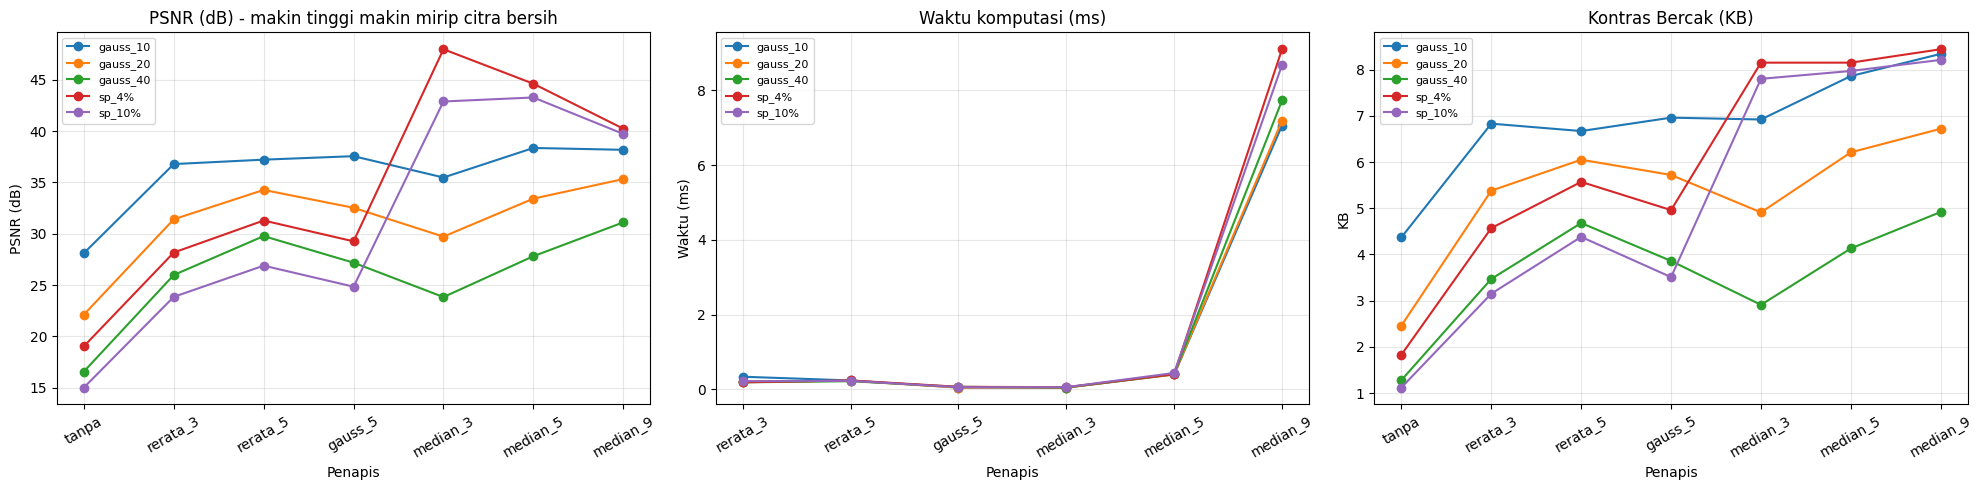

In [4]:
# Perbandingan Penapis dan Jenis Derau
rng = np.random.default_rng(42)

# Fungsi pembangkit derau Gaussian
def derau_gauss(img, sd):
    return np.clip(
        img.astype(float) + rng.normal(0, sd, img.shape),
        0, 255
    ).astype(np.uint8)

# Fungsi pembangkit derau garam-merica
def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out

# Fungsi pengukuran waktu
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

# Citra acuan
nama = "teh_041.png"

bersih = cv2.imread(
    os.path.join(DATA_DIR, "bersih", nama)
)
bersih = cv2.cvtColor(bersih, cv2.COLOR_BGR2GRAY)

md = cv2.imread(
    os.path.join(DATA_DIR, "mask_daun", nama), 0
)
mb = cv2.imread(
    os.path.join(DATA_DIR, "mask_bercak", nama), 0
)

# Membuat lima jenis derau
derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}

# Enam jenis penapis
penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

# Menghitung PSNR, waktu, dan KB
baris = []

for dn, d in derau.items():

    baris.append([
        dn,
        "tanpa",
        cv2.PSNR(bersih, d),
        0.0,
        kontras_bercak(d, md, mb)
    ])

    for pn, f in penapis.items():

        out = f(d)

        baris.append([
            dn,
            pn,
            cv2.PSNR(bersih, out),
            ukur_waktu(f, d),
            kontras_bercak(out, md, mb)
        ])

tabel = pd.DataFrame(
    baris,
    columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]
).round(2)

print("HASIL PERBANDINGAN PENAPIS")
display(tabel)

# Simpan hasil
tabel.to_csv(
    os.path.join(HASIL_DIR, "b4_tabel_penapis.csv"),
    index=False
)

# Tabel 11: Gaussian 20 dan garam-merica 4% berdampingan
urutan_penapis = ["tanpa"] + list(penapis.keys())
g20 = tabel[tabel["derau"] == "gauss_20"].set_index("penapis")[["PSNR_dB", "waktu_ms", "KB"]]
sp4 = tabel[tabel["derau"] == "sp_4%"].set_index("penapis")[["PSNR_dB", "waktu_ms", "KB"]]
g20.columns = ["Gaussian 20: PSNR (dB)", "Gaussian 20: waktu (ms)", "Gaussian 20: KB"]
sp4.columns = ["Garam-merica 4%: PSNR (dB)", "Garam-merica 4%: waktu (ms)", "Garam-merica 4%: KB"]
tabel11 = g20.join(sp4).reindex(urutan_penapis)

print("\nTABEL 11. PERBANDINGAN PENAPIS")
display(tabel11)
tabel11.to_csv(os.path.join(HASIL_DIR, "b4_tabel11.csv"))

# Grafik PSNR, waktu, dan KB dalam satu gambar
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for dn in derau.keys():
    data = tabel[tabel["derau"] == dn]
    axes[0].plot(data["penapis"], data["PSNR_dB"], marker="o", label=dn)
    data_f = data[data["penapis"] != "tanpa"]   # "tanpa" tidak punya waktu proses
    axes[1].plot(data_f["penapis"], data_f["waktu_ms"], marker="o", label=dn)
    axes[2].plot(data["penapis"], data["KB"], marker="o", label=dn)

judul = ["PSNR (dB) - makin tinggi makin mirip citra bersih",
         "Waktu komputasi (ms)",
         "Kontras Bercak (KB)"]
for ax, jd in zip(axes, judul):
    ax.set_title(jd)
    ax.set_xlabel("Penapis")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("PSNR (dB)")
axes[1].set_ylabel("Waktu (ms)")
axes[2].set_ylabel("KB")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b4_grafik_psnr_waktu_kb.png"), dpi=150, bbox_inches="tight")
plt.show()

# 4.4 Apakah bercak kecil tetap terjaga?

RERATA dI DAN KB PER UKURAN KERNEL MEDIAN (20 citra kelas ringan)


,dI,KB
kernel,,
1,27.58,4.29
3,28.08,4.44
5,27.19,4.37
9,21.14,3.95
15,8.35,2.26


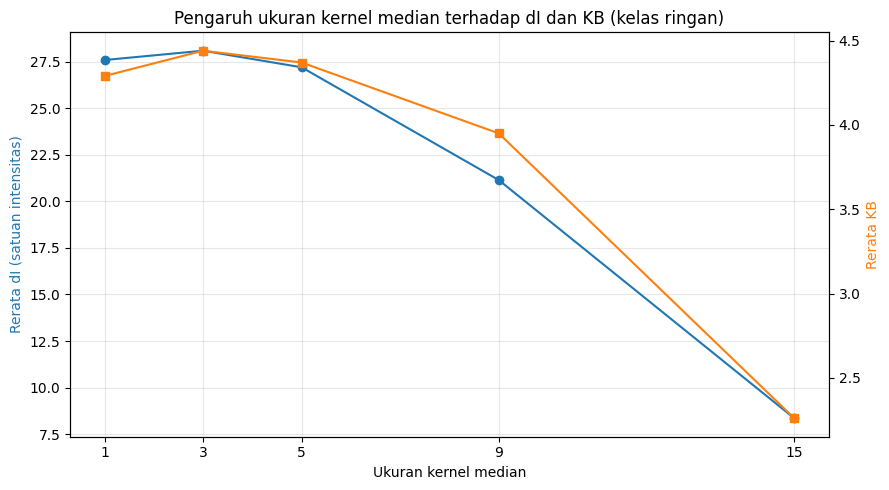

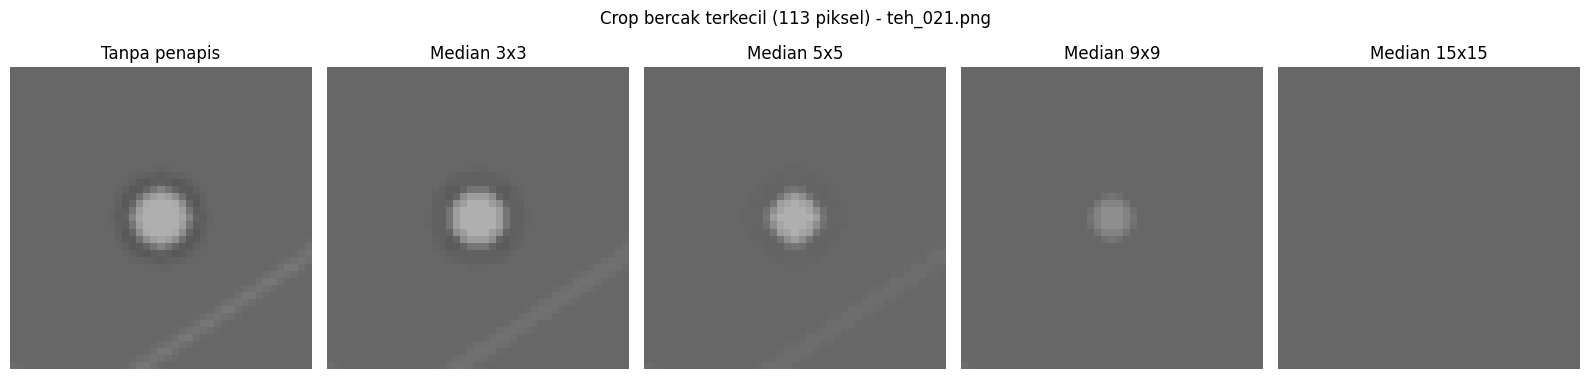

In [5]:
# Pengaruh Ukuran Kernel Median pada Bercak Kecil
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    return abs(k[bercak].mean() - k[sehat].mean())


# Membaca label citra
label = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))
data_ringan = label[label["kelas"] == "ringan"]

daftar_kernel = [1, 3, 5, 9, 15]
baris = []

# Menghitung dI dan KB pada 20 citra kelas ringan
for nm in data_ringan["nama_file"]:
    g = cv2.imread(os.path.join(DATA_DIR, "bersih", nm), 0)
    md2 = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nm), 0)
    mb2 = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nm), 0)

    for k in daftar_kernel:   # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k,
                      selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])

# Rerata dI dan KB per ukuran kernel
rata_median = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print("RERATA dI DAN KB PER UKURAN KERNEL MEDIAN (20 citra kelas ringan)")
display(rata_median)
rata_median.to_csv(os.path.join(HASIL_DIR, "b4_pengaruh_kernel_median.csv"))

# Grafik dI dan KB terhadap ukuran kernel (dua sumbu y)
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(rata_median.index, rata_median["dI"], marker="o", color="tab:blue", label="dI")
ax1.set_xlabel("Ukuran kernel median")
ax1.set_ylabel("Rerata dI (satuan intensitas)", color="tab:blue")
ax1.set_xticks(daftar_kernel)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(rata_median.index, rata_median["KB"], marker="s", color="tab:orange", label="KB")
ax2.set_ylabel("Rerata KB", color="tab:orange")

plt.title("Pengaruh ukuran kernel median terhadap dI dan KB (kelas ringan)")
fig.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b4_dI_kernel.png"), dpi=150, bbox_inches="tight")
plt.show()


# Crop satu bercak KECIL untuk perbandingan visual
nm_crop = data_ringan.iloc[0]["nama_file"]

g = cv2.imread(os.path.join(DATA_DIR, "bersih", nm_crop), 0)
mb2 = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nm_crop), 0)

jumlah, label_komponen, stats_cc, pusat = cv2.connectedComponentsWithStats(
    (mb2 > 0).astype(np.uint8), 8
)

if jumlah > 1:
    # Memilih bercak dengan luas terkecil
    komponen = 1 + np.argmin(stats_cc[1:, cv2.CC_STAT_AREA])
    x, y, w, h, luas = stats_cc[komponen]

    margin = 15
    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(g.shape[1], x + w + margin)
    y2 = min(g.shape[0], y + h + margin)

    plt.figure(figsize=(16, 4))

    for i, k in enumerate(daftar_kernel):
        # Tapis citra utuh dulu, baru dipotong (agar tepi potongan tidak terdistorsi)
        utuh = g if k == 1 else cv2.medianBlur(g, k)
        potong = utuh[y1:y2, x1:x2]

        plt.subplot(1, 5, i + 1)
        plt.imshow(potong, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        plt.title("Tanpa penapis" if k == 1 else f"Median {k}x{k}")
        plt.axis("off")

    plt.suptitle(f"Crop bercak terkecil ({luas} piksel) - {nm_crop}")
    plt.tight_layout()
    plt.savefig(os.path.join(HASIL_DIR, "b4_crop_bercak.png"), dpi=150, bbox_inches="tight")
    plt.show()

else:
    print("Bercak tidak ditemukan pada citra yang dipilih.")

# 4.5 Urutan meredam derau dan menajamkan

Gaussian: tajam->redam PSNR=30.41 sigma_latar=7.8 | redam->tajam PSNR=30.20 sigma_latar=8.2
Median: tajam->redam PSNR=30.14 sigma_latar=8.1 | redam->tajam PSNR=31.09 sigma_latar=7.2


,Penapis peredam,Urutan,PSNR (dB),Sigma latar
0,Gaussian,tajam -> redam,30.41,7.8
1,Gaussian,redam -> tajam,30.20,8.2
2,Median,tajam -> redam,30.14,8.1
3,Median,redam -> tajam,31.09,7.2


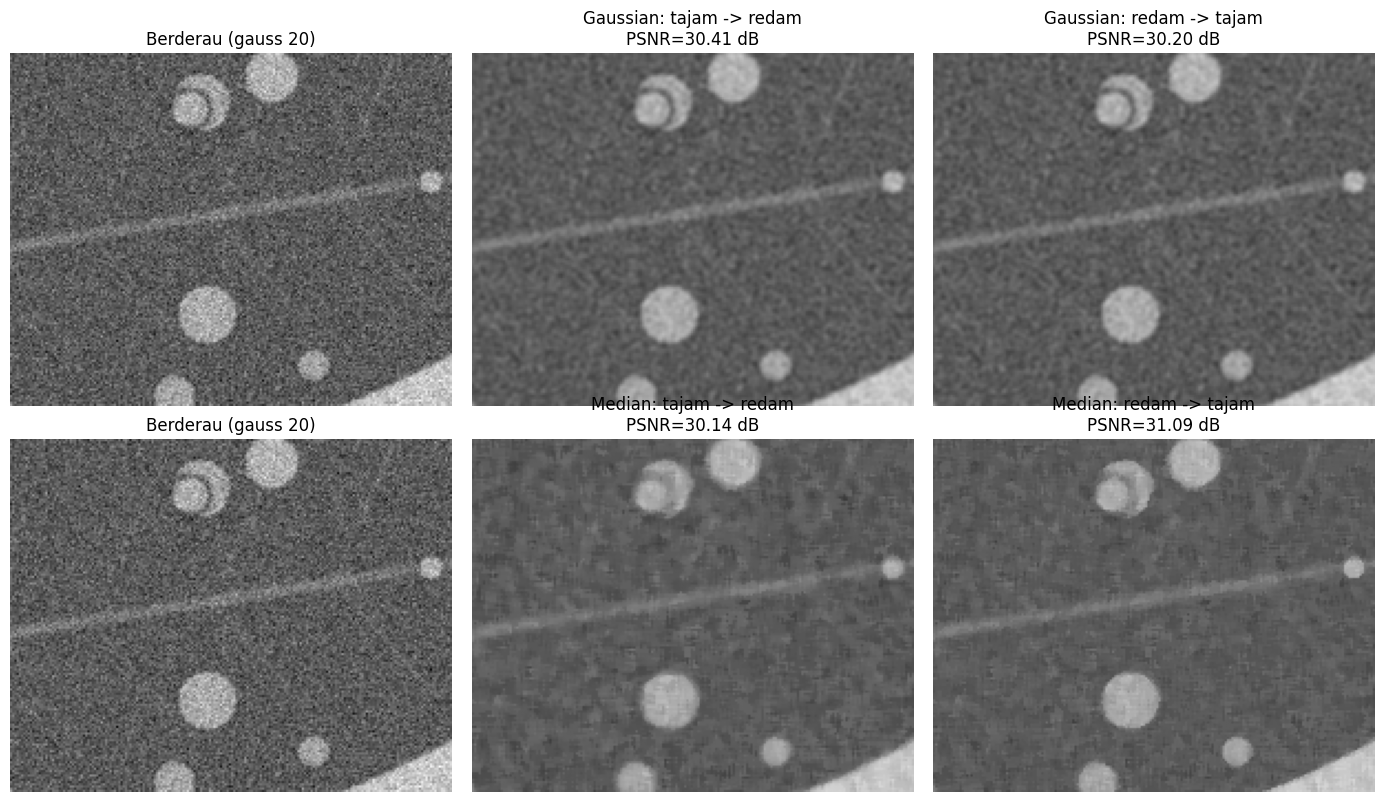

In [6]:
# Pengaruh Urutan Penajaman dan Peredaman Derau
# Fungsi penajaman (Unsharp Masking)
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)


# Menggunakan citra dengan derau Gaussian standar deviasi 20
noisy = derau["gauss_20"]

# Area latar belakang (seharusnya rata)
latar = md == 0

baris_urutan = []
panel_urutan = []

# Membandingkan dua urutan proses
for nm, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():

    # Penajaman kemudian peredaman
    A = redam(unsharp(noisy))

    # Peredaman kemudian penajaman
    B = unsharp(redam(noisy))

    print(
        f"{nm}: "
        f"tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
        f"sigma_latar={A[latar].std():.1f} | "
        f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} "
        f"sigma_latar={B[latar].std():.1f}"
    )

    baris_urutan.append([nm, "tajam -> redam",
                         round(cv2.PSNR(bersih, A), 2), round(float(A[latar].std()), 1)])
    baris_urutan.append([nm, "redam -> tajam",
                         round(cv2.PSNR(bersih, B), 2), round(float(B[latar].std()), 1)])
    panel_urutan.append((nm, A, B))

# Tabel hasil urutan
tabel_urutan = pd.DataFrame(baris_urutan,
                            columns=["Penapis peredam", "Urutan", "PSNR (dB)", "Sigma latar"])
display(tabel_urutan)
tabel_urutan.to_csv(os.path.join(HASIL_DIR, "b4_urutan_tajam.csv"), index=False)

# Panel visual: potongan area daun agar butiran derau terlihat jelas
y1, y2, x1, x2 = 160, 320, 220, 420

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, (nm, A, B) in enumerate(panel_urutan):
    for j, (citra, jd) in enumerate([(noisy, "Berderau (gauss 20)"),
                                     (A, "tajam -> redam"),
                                     (B, "redam -> tajam")]):
        axes[i, j].imshow(citra[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255)
        judul = jd if j == 0 else f"{nm}: {jd}\nPSNR={cv2.PSNR(bersih, citra):.2f} dB"
        axes[i, j].set_title(judul)
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b4_urutan_tajam.png"), dpi=150, bbox_inches="tight")
plt.show()

# 4.6 Pengujian pada Citra dengan Derau Sensor Bawaan.

In [7]:
# Pengujian Penapis pada Citra dengan Derau Sensor Bawaan
# 12 citra kondisi normal: teh_001, teh_006, teh_011, ..., teh_056
daftar_citra = [f"teh_{i:03d}.png" for i in range(1, 57, 5)]

# Penapis yang dibandingkan (median_3 = parameter praproses.py)
penapis_uji = {
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
}

baris = []

for nm in daftar_citra:

    # Citra dengan derau sensor bawaan dan pasangan bersihnya
    citra_derau = cv2.imread(os.path.join(DATA_DIR, "citra", nm), 0)
    citra_bersih = cv2.imread(os.path.join(DATA_DIR, "bersih", nm), 0)

    if citra_derau is None or citra_bersih is None:
        print("Citra tidak ditemukan:", nm)
        continue

    data = {"nama_file": nm, "PSNR_sebelum": cv2.PSNR(citra_bersih, citra_derau)}

    for pn, f in penapis_uji.items():
        data[f"PSNR_{pn}"] = cv2.PSNR(citra_bersih, f(citra_derau))

    baris.append(data)

hasil_sensor = pd.DataFrame(baris).round(2)

print("HASIL PENGUJIAN 12 CITRA DENGAN DERAU SENSOR BAWAAN")
display(hasil_sensor)

# Rata-rata dan kenaikan PSNR tiap penapis
ringkas = []
for pn in penapis_uji:
    rata = hasil_sensor[f"PSNR_{pn}"].mean()
    naik = (hasil_sensor[f"PSNR_{pn}"] - hasil_sensor["PSNR_sebelum"]).mean()
    ringkas.append([pn, round(hasil_sensor["PSNR_sebelum"].mean(), 2), round(rata, 2), round(naik, 2)])

tabel_ringkas_sensor = pd.DataFrame(
    ringkas, columns=["penapis", "PSNR_sebelum_rata2", "PSNR_sesudah_rata2", "kenaikan_dB"]
)
print("\nRINGKASAN RATA-RATA PSNR")
display(tabel_ringkas_sensor)

hasil_sensor.to_csv(os.path.join(HASIL_DIR, "b4_pengujian_derau_sensor.csv"), index=False)
tabel_ringkas_sensor.to_csv(os.path.join(HASIL_DIR, "b4_ringkasan_derau_sensor.csv"), index=False)

HASIL PENGUJIAN 12 CITRA DENGAN DERAU SENSOR BAWAAN


,nama_file,PSNR_sebelum,PSNR_median_3,PSNR_median_5,PSNR_gauss_5
0,teh_001.png,34.16,41.05,43.03,42.24
1,teh_006.png,32.48,39.64,42.22,41.44
2,teh_011.png,34.36,41.24,43.33,42.35
3,teh_016.png,32.82,39.92,42.35,41.15
4,teh_021.png,28.85,36.21,39.24,38.49
5,teh_026.png,34.08,40.99,42.97,42.33
6,teh_031.png,35.22,42.00,43.50,42.50
7,teh_036.png,31.98,39.15,41.63,40.80
8,teh_041.png,33.66,40.53,41.93,40.88
9,teh_046.png,28.88,36.20,38.80,38.17



RINGKASAN RATA-RATA PSNR


,penapis,PSNR_sebelum_rata2,PSNR_sesudah_rata2,kenaikan_dB
0,median_3,32.39,39.44,7.05
1,median_5,32.39,41.61,9.22
2,gauss_5,32.39,40.80,8.41
